# The one-slide answer: claim, evidence, caveat, action: what does a slide carry?

**Week 4, Tuesday, concept notebook 1 of 5, beside chapter 1 of the deck.** Ramesh's kirana shop is invented: it opened two more hours a day from October, and every day and every rupee in this notebook is an invented number written by the day's seeded generator.

**Who needs the answer.** Ramesh (invented), who must decide whether the longer hours
stay, and his son, who argued for them and loses if they go. A slide that quotes the wrong
denominator lets each of them read a different verdict from the same rupees, and the helper
is paid for two hours nobody has priced.

**The questions on the way.** What do the 56 days say per day, per hour and per customer?
Which denominator prices Ramesh's decision? Does the fall per hour hold on every day? What
does the slide say in its four parts? What does the trap sentence get wrong?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# Ramesh's 56 days: four weeks in September at 10 hours a day, four in October at 12; all invented
days = pd.read_csv("../data/C2_W04_D02_kirana_days_STUDENT.csv")
check("56 days, 28 in each month", len(days) == 56 and (days.month.value_counts() == 28).all())
check("10 hours a day in September and 12 in October",
      set(days[days.month == "September"].hours_open) == {10} and set(days[days.month == "October"].hours_open) == {12})
print(days.to_string(index=False))           # the whole table, one row per day, every number invented

PASS 56 days, 28 in each month
PASS 10 hours a day in September and 12 in October
    month  day  hours_open  customers  sales_rs rain_day festival_day
September    1          10        117     11820       no           no
September    2          10        118     11720       no           no
September    3          10        121     12140       no           no
September    4          10        118     11640       no           no
September    5          10        120     12060       no           no
September    6          10        121     12100       no           no
September    7          10        123     12320       no           no
September    8          10        117     11820       no           no
September    9          10        105     10420      yes           no
September   10          10        119     11940       no           no
September   11          10        118     11640       no           no
September   12          10        120     12060       no           no
Septembe

## What do the 56 days say per day, per hour and per customer?

A **rate** is one number divided by another, and the number below the line is its
**denominator**: sales per day divide by days, sales per hour by hours open, sales per
customer by customers. Since Week 1 a rate that does not name its denominator has been a
rumour.

Count by hand first, on each month's totals. September sold Rs 3.33 lakh over 28 days, Rs
11,900 a day, and at 10 hours a day that is Rs 1,190 an hour. October sold Rs 3.53 lakh
over 28 days, Rs 12,600 a day, and at 12 hours a day Rs 1,050 an hour. Each month's
customers spent Rs 100 each: 3,332 customers in September and 3,528 in October.

**Predict before you run.** The son says the shop earns more; the father says each hour
earns less. Who is right?

a) The son, since sales a day rose
b) The father, since sales an hour fell
c) Both, each on a different denominator
d) Neither, since sales per customer did not move

            sales  days  hours  customers  per_day  per_hour  per_customer
month                                                                     
September  333200    28   10.0       3332  11900.0    1190.0         100.0
October    352800    28   12.0       3528  12600.0    1050.0         100.0
October on September: per day +5.9 percent, per hour -11.8 percent, per customer flat
PASS by hand and by code: Rs 11,900 and Rs 12,600 a day
PASS by hand and by code: Rs 1,190 and Rs 1,050 an hour
PASS by hand and by code: Rs 100 a customer in both months


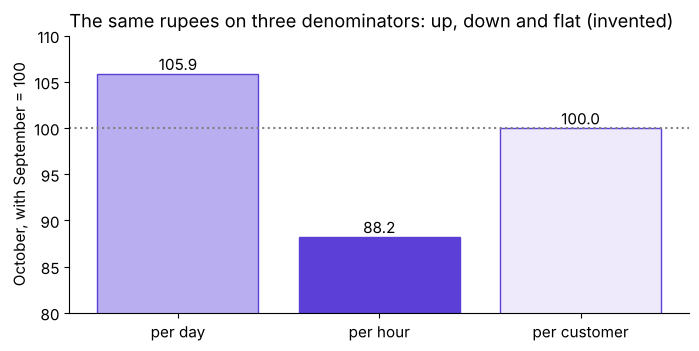

In [2]:
# Add up each month, then divide the same rupees by days, by hours open and by customers
m = days.groupby("month").agg(sales=("sales_rs", "sum"), days=("day", "count"),
                              hours=("hours_open", "mean"), customers=("customers", "sum"))
m = m.loc[["September", "October"]]
m["per_day"] = m.sales / m.days                  # Rs a day
m["per_hour"] = m.per_day / m.hours              # Rs an hour open
m["per_customer"] = m.sales / m.customers        # Rs a customer
print(m.round(1).to_string())
chg = (m.loc["October"] / m.loc["September"] - 1) * 100
print(f"October on September: per day {chg.per_day:+.1f} percent, per hour {chg.per_hour:+.1f} percent, per customer flat")
check("by hand and by code: Rs 11,900 and Rs 12,600 a day", list(m.per_day) == [11900, 12600])
check("by hand and by code: Rs 1,190 and Rs 1,050 an hour", list(m.per_hour) == [1190, 1050])
check("by hand and by code: Rs 100 a customer in both months", list(m.per_customer) == [100, 100])

reads = ["per_day", "per_hour", "per_customer"]
index = m.loc["October", reads] / m.loc["September", reads] * 100     # September = 100
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(["per day", "per hour", "per customer"], index, color=[LILAC, VIOLET, PALE], edgecolor=VIOLET)
ax.bar_label(bars, fmt="%.1f")
ax.axhline(100, color="gray", ls=":")
ax.set_ylim(80, 110)
ax.set_ylabel("October, with September = 100")
ax.set_title("The same rupees on three denominators: up, down and flat (invented)", loc="left")
plt.show()

**What happened.** The answer is c. Per day the shop is up Rs 700, 5.9 percent, which is
the son's sentence; per hour it is down 11.8 percent, which is the father's; per customer
it is flat at Rs 100. Three honest divisions of the same rupees gave three verdicts, so the
denominator decides which sentence the slide carries.

## Which denominator prices Ramesh's decision?

The decision on the table is whether the two extra hours pay, and a decision about hours is
priced per hour. The cell names the unit each question buys or loses, then reads the rate in
that unit.

**Predict before you run.** Ramesh's accountant asks a different question: did each
customer spend less after the change? Which rate answers her?

a) Sales per day
b) Sales per hour
c) Sales per customer
d) Total sales over the four weeks

In [3]:
# the rate a decision is priced in: its denominator is the unit the decision buys or loses
for asker, unit in [("Ramesh, do the two extra hours pay?", "hour"),
                    ("The accountant, does each customer spend less?", "customer")]:
    before, after = m[f"per_{unit}"]
    print(f"{asker:<47} sales per {unit}: Rs {before:,.0f} in September, Rs {after:,.0f} in October")
check("sales per hour fell from September to October", m.per_hour.iloc[1] < m.per_hour.iloc[0])
check("per customer did not move between the months", m.per_customer.nunique() == 1)

Ramesh, do the two extra hours pay?             sales per hour: Rs 1,190 in September, Rs 1,050 in October
The accountant, does each customer spend less?  sales per customer: Rs 100 in September, Rs 100 in October
PASS sales per hour fell from September to October
PASS per customer did not move between the months


**What happened.** The answer is c: her question is about customers, so it is read per
customer, and it says nobody spent less. Ramesh's question is about hours, so his slide is
priced per hour, with sales per customer beside it.

## Does the fall per hour hold on every day, or only on a few?

A monthly average can hide a handful of bad days. The chart draws sales per hour for each of
the 56 days, with the rain days as dots and October's festival fortnight shaded, and it
carries the claim as its title.

**Predict before you run.** How many October days earned more per hour than the weakest dry
September day?

a) None
b) About a quarter of them
c) About half
d) Only the festival days

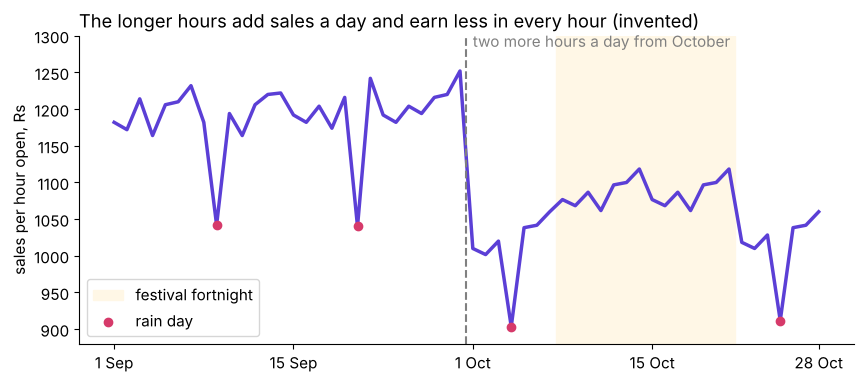

October days above the weakest dry September day, per hour: none
PASS every October day earns less per hour than every dry September day
PASS the festival days sell more a day than October's other days


In [4]:
days["per_hour"] = days.sales_rs / days.hours_open
days["x"] = range(1, len(days) + 1)
fest = days[days.festival_day == "yes"].x
rain = days[days.rain_day == "yes"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(fest.min() - 0.5, fest.max() + 0.5, color="#FFF7E6", label="festival fortnight")
ax.plot(days.x, days.per_hour, color=VIOLET, lw=2.5)
ax.scatter(rain.x, rain.per_hour, color=ROSE, zorder=3, label="rain day")
ax.axvline(28.5, color="gray", ls="--")
ax.text(29, 1285, "two more hours a day from October", color="gray")
ax.set_xticks([1, 15, 29, 43, 56], ["1 Sep", "15 Sep", "1 Oct", "15 Oct", "28 Oct"])
ax.set_ylim(880, 1300)
ax.set_ylabel("sales per hour open, Rs")
ax.set_title("The longer hours add sales a day and earn less in every hour (invented)", loc="left")
ax.legend(loc="lower left")
plt.show()

sep, octo = days[days.month == "September"], days[days.month == "October"]
weakest_dry = sep[sep.rain_day == "no"].per_hour.min()
above = int((octo.per_hour > weakest_dry).sum())
print("October days above the weakest dry September day, per hour:", "none" if above == 0 else above)
check("every October day earns less per hour than every dry September day", above == 0)
check("the festival days sell more a day than October's other days",
      octo[octo.festival_day == "yes"].sales_rs.mean() > octo[octo.festival_day == "no"].sales_rs.mean())

**What happened.** The answer is a. Every October day, the festival days included, earned
less per hour than every dry September day, so the fall is no handful of bad days. The
festival days do sell more a day than October's other days, and that is the caveat: part of
the extra Rs 700 a day may be the season, which this data cannot separate yet.

## What does the slide say in its four parts?

Named last, the rule the chapter builds: a slide that carries a decision has four parts, in
the order a reader needs them. The **claim** is the title, a sentence with a verb saying
what is true and what to do. The **evidence** is one number with its denominator, or one
chart. The **caveat** is what the evidence cannot show yet, beside it. The **action** says
what to do, its cost in rupees and weeks, and who signs. Together they are the one-slide
answer: claim, evidence, caveat, action. The cell below writes them in that order, and the
picture draws them where a reader meets them.

   claim: The longer hours add Rs 700 a day but earn less per hour, so count the evening on its own before deciding
evidence: sales per hour: Rs 1,190 in September, Rs 1,050 in October; each added hour at most Rs 350; sales per customer held at Rs 100
  caveat: A festival fortnight fell inside October, so part of the extra Rs 700 a day may be the season
  action: Keep the hours through November, count the evening's sales apart and decide after thirty days; the helper's two extra hours cost Rs 170 a day, and Ramesh signs


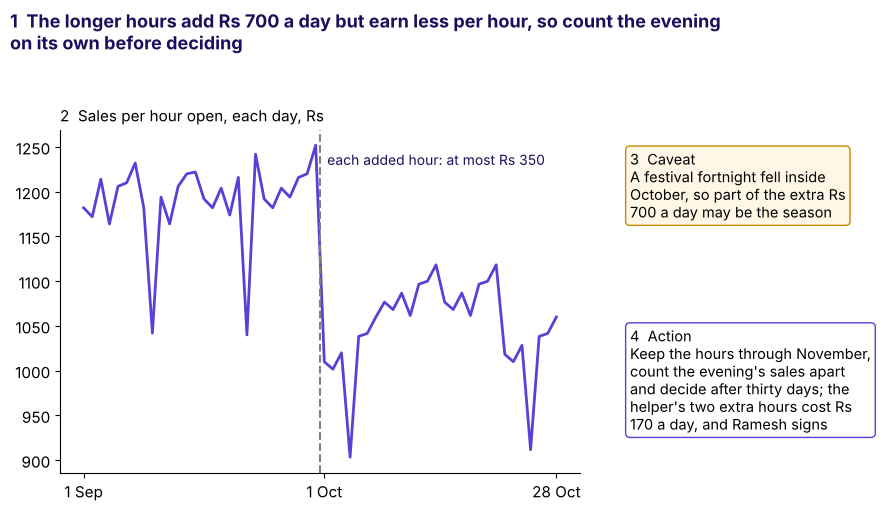

PASS the evidence names its denominator
PASS the evidence carries the added hours' own rate
PASS the action carries a cost in rupees and who signs
PASS the son can repeat the title, since it carries his Rs 700


In [5]:
added = m.per_day.diff().iloc[-1] / m.hours.diff().iloc[-1]   # what each of the two added hours sold, at most
before, after = m.per_hour
slide = {                                                     # the four parts, in the order a reader needs them
    "claim": "The longer hours add Rs 700 a day but earn less per hour, so count the evening on its own before deciding",
    "evidence": (f"sales per hour: Rs {before:,.0f} in September, Rs {after:,.0f} in October; "
                 f"each added hour at most Rs {added:,.0f}; sales per customer held at Rs 100"),
    "caveat": "A festival fortnight fell inside October, so part of the extra Rs 700 a day may be the season",
    "action": ("Keep the hours through November, count the evening's sales apart and decide after thirty days; "
               "the helper's two extra hours cost Rs 170 a day, and Ramesh signs")}
for part, text in slide.items():
    print(f"{part:>8}: {text}")

fig = plt.figure(figsize=(10, 5.2))
fig.text(0.02, 0.97, "1  " + textwrap.fill(slide["claim"], 80), fontsize=13, weight="bold", color=INK, va="top")
ev = fig.add_axes([0.07, 0.08, 0.52, 0.66])
ev.plot(days.x, days.per_hour, color=VIOLET, lw=2)
ev.axvline(28.5, color="gray", ls="--")
ev.set_xticks([1, 29, 56], ["1 Sep", "1 Oct", "28 Oct"])
ev.set_title("2  Sales per hour open, each day, Rs", loc="left", fontsize=11)
ev.text(42, 1230, f"each added hour: at most Rs {added:,.0f}", ha="center", fontsize=10, color=INK)
fig.text(0.64, 0.70, "3  Caveat\n" + textwrap.fill(slide["caveat"], 34), fontsize=10.5, va="top",
         bbox=dict(boxstyle="round", fc="#FFF7E6", ec=AMBER))
fig.text(0.64, 0.36, "4  Action\n" + textwrap.fill(slide["action"], 34), fontsize=10.5, va="top",
         bbox=dict(boxstyle="round", fc="white", ec=VIOLET))
plt.show()
check("the evidence names its denominator", " per " in slide["evidence"])
check("the evidence carries the added hours' own rate", "Rs 350" in slide["evidence"])
check("the action carries a cost in rupees and who signs", "Rs" in slide["action"] and "signs" in slide["action"])
check("the son can repeat the title, since it carries his Rs 700", "Rs 700" in slide["claim"])

## What does the trap sentence get wrong?

**The plausible wrong answer.** "Sales a day rose from Rs 11,900 to Rs 12,600, so the longer
hours work; keep them." Every rupee in it is right, and a hurried read reaches it in one
line.

**Predict before you run.** What bought the extra Rs 700 a day?

a) More customers, each spending more
b) Two more hours a day, each selling far less than an old hour
c) Higher prices on the same goods
d) The festival fortnight alone

In [6]:
hurried = m.per_day.diff().iloc[-1]                  # sales a day, October less September
extra_hours = m.hours.diff().iloc[-1]
added = hurried / extra_hours                        # the most each added hour can have sold
print(f"the hurried read: Rs {hurried:,.0f} more a day, so keep the hours")
print(f"what bought the rise: {extra_hours:.0f} more hours a day, at most Rs {added:,.0f} of sales in each,")
print(f"against Rs {m.per_hour.iloc[0]:,.0f} in each of September's ten hours")
check("the hurried read is true to the rupee", hurried == 700)
check("and it was bought with two more hours a day", extra_hours == 2)
check("each added hour sold at most Rs 350, under a third of an old hour",
      added == 350 and added < m.per_hour.iloc[0] / 3)

the hurried read: Rs 700 more a day, so keep the hours
what bought the rise: 2 more hours a day, at most Rs 350 of sales in each,
against Rs 1,190 in each of September's ten hours
PASS the hurried read is true to the rupee
PASS and it was bought with two more hours a day
PASS each added hour sold at most Rs 350, under a third of an old hour


**Why it is wrong.** The answer is b: the rise was bought with two more hours a day, and each
of them sold at most Rs 350, against Rs 1,190 in each of the old ten. It is the most they can
have sold, since the festival may have lifted the old hours too. Rs 700 is sales before the
cost of the goods, and the shop's records hold no figure for what the goods cost, so the
sentence would keep paying the helper Rs 170 a day without asking whether the evening earns
it. An average per hour falls whenever quieter hours join it; the Rs 350 says how much
quieter. **The check:** divide by what the decision buys, here the two extra hours, before
reading any number. **The fix:** the evidence is per hour, Rs 1,190 to Rs 1,050 with the
added hours' Rs 350 beside it, and the action counts the evening's sales on their own for a
month.

**Your turn.** A second example of the same shape, also invented: an auto driver earned Rs
1,800 on Monday from 20 rides in 9 hours, and Rs 1,800 on Tuesday from 18 rides in 12
hours. Read his two days per day, per ride and per hour, then divide by what his question
buys, "should I drive the longer day again?": the three added hours. Fill the blanks, type
the lines into the empty cell below and run them; the checks print PASS when the reads are
right.

```python
auto = pd.DataFrame({"rs": [1800, 1800], "rides": [20, 18], "hours": [9, 12]},
                    index=["Monday", "Tuesday"])
auto["per_ride"] = auto.rs / auto.___
auto["per_hour"] = auto.rs / auto.___
added = auto.rs.diff().iloc[-1] / auto.hours.diff().iloc[-1]   # what each added hour brought
print(auto)
print("each of the three added hours brought Rs", added)
check("per day is flat", auto.rs.nunique() == 1)
check("per ride rose while per hour fell",
      auto.per_ride.is_monotonic_increasing and auto.per_hour.is_monotonic_decreasing)
check("the three added hours brought nothing", added == 0)
```

## Which rules does the chapter leave?

1. The title is the claim: a sentence with a verb that says what is true and what to do.
2. The evidence is one number divided by what the decision buys, with its window, or one
   chart.
3. The caveat sits beside the evidence, in plain sight.
4. The action names what to do, its cost in rupees and weeks, and who signs.

A slide has worked when the person who loses under it can repeat it accurately while
disagreeing with it.

**In the interview.** [S] Present a recommendation to a non-technical stakeholder in two
minutes: open on the claim, then one number with its denominator.

**Where it is used next.** Notebook 02 sorts what leaves Ramesh's slide. Chapter 4's
notebook, `C2_W04_D02_04_case_one_slide_answer_three_denominators_STUDENT.ipynb`, runs the
same three divisions on Uber's twelve driver-weeks and rebuilds the city head's slide in
these four parts.